# Sección 5: construcción y entrenamiento de las redes

Este notebook entrena y evalúa las redes del laboratorio sobre el mismo panel de 100 clientes, la misma semilla y la misma función `backtest`. Las corridas largas se ejecutan por etapas con `scripts/run_entrenamiento.py` (cada etapa guarda CSV en `artifacts/`) y aquí se leen esos artefactos; con `EJECUTAR_CORRIDAS = True` las celdas relanzan las etapas.

| Etapa | Comando |
|---|---|
| Iteraciones 5.2 (solo validación) | `python scripts/run_entrenamiento.py iteraciones` |
| Prueba de las redes propias | `python scripts/run_entrenamiento.py prueba-propias` |
| NeuralForecast (N-HiTS, TCN, PatchTST, iTransformer, DeepAR) | `python scripts/run_entrenamiento.py nixtla` |
| PatchTST con 3 y 12 meses | `python scripts/run_entrenamiento.py patchtst-historia` |
| Sensibilidad a la historia | `python scripts/run_entrenamiento.py historia` |
| Local contra global (5.3) | `python scripts/run_entrenamiento.py local-global` |
| Tres semillas | `python scripts/run_entrenamiento.py semillas` |
| Reentrenamiento mensual | `python scripts/run_entrenamiento.py mensual` |

**Decisiones comunes.**
- Ventanas de entrenamiento con stride de 1 hora cuyo objetivo completo cae en train (hasta 2014-06-30 23:00), muestreadas directamente en GPU.
- Pérdida L1 en escala normalizada; Adam, recorte de gradiente a 1 y early stopping por MASE de validación (paciencia 4, máximo 25 epochs).
- La validación usa los 92 orígenes diarios de julio a septiembre, con el mismo protocolo que la prueba.
- La prueba se corre una sola vez por modelo con `backtest()` y los pesos elegidos en validación.
- Los análisis repetidos (semillas, local/global, mensual) usan `rolling_forecasts`, el evaluador vectorizado que `tests/test_training.py` verifica contra `backtest`.

In [1]:
from pathlib import Path
import subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from forecasting_lab.config import ExperimentConfig
from forecasting_lab.results import plot_history_sensitivity
from forecasting_lab.training import (PanelTensors, daily_origins, predict_positions,
                                      rolling_forecasts, forecast_errors)

sys.path.insert(0, "scripts")
from run_entrenamiento import base_configs, load_panel, load_run, run_id_of

CONFIG = ExperimentConfig()
EJECUTAR_CORRIDAS = False
ARTEFACTOS = Path("artifacts")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

if EJECUTAR_CORRIDAS:
    for etapa in ["iteraciones", "prueba-propias", "nixtla", "patchtst-historia", "historia",
                  "local-global", "semillas", "mensual"]:
        subprocess.run([sys.executable, "scripts/run_entrenamiento.py", etapa], check=True)

panel = load_panel(ARTEFACTOS)
iteraciones = pd.read_csv(ARTEFACTOS / "iteraciones_entrenamiento.csv")
resumen = pd.read_csv(ARTEFACTOS / "iteraciones_resumen.csv")
resultados = pd.read_csv(ARTEFACTOS / "resultados_redes.csv")
print(panel.shape, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible")

(26304, 100) | GPU: NVIDIA GeForce RTX 5070 Ti


## 5. Construcción y entrenamiento

Las redes propias usan las clases de `models.py`:
- **MLP multi-salida.** Recibe el objetivo y las 7 covariables de calendario de las `L` horas.
- **DLinear y NLinear.** Son univariados.
- **LSTM multi-salida.** Una capa densa devuelve los 24 pasos.
- **LSTM autorregresiva.** Realimenta su predicción junto con el calendario de la hora siguiente.
- **Seq2seq.** Codificador LSTM; el decoder recibe el calendario futuro.

Los modelos de librería usan NeuralForecast. N-HiTS, TCN, iTransformer y DeepAR reciben el calendario futuro; PatchTST no admite exógenas. Todas las series entran con z-score por serie ajustado en train. El escalado por ventana de NeuralForecast divide por `eps` en las ventanas constantes de clientes con tramos en cero (por ejemplo MT_223) y producía pérdidas NaN.

### Tabla de resultados en prueba de las redes

In [2]:
columnas = ["modelo", "familia", "L", "estrategia", "usa_covariables", "total_parameters",
            "trainable_parameters", "training_seconds", "inference_seconds", "hardware",
            "validation_mase", "mae", "rmse", "wape", "mase", "mase_navidad", "pinball_loss", "cobertura_p10_p90"]
resultados.sort_values("mase")[[c for c in columnas if c in resultados]].round(4)

,modelo,familia,L,estrategia,usa_covariables,total_parameters,trainable_parameters,training_seconds,inference_seconds,hardware,validation_mase,mae,rmse,wape,mase,mase_navidad,pinball_loss,cobertura_p10_p90
0,N-HiTS,Residuales y convolucionales,168,multi-salida,True,4193826,4193826,244.2065,899.8601,GPU NVIDIA GeForce RTX 5070 Ti,0.7936,66.7843,608.1080,0.0757,0.7701,1.3965,NaN,NaN
3,iTransformer,Atención,168,multi-salida,True,6503448,6503448,905.6355,642.5268,GPU NVIDIA GeForce RTX 5070 Ti,0.8347,72.1409,651.5431,0.0818,0.7852,1.2383,NaN,NaN
5,LSTM,Recurrentes,168,multi-salida,True,73752,73752,692.5158,598.8018,GPU NVIDIA GeForce RTX 5070 Ti,0.8266,67.9859,603.2771,0.0771,0.7994,1.4558,NaN,NaN
6,MLP,MLP y lineales,336,multi-salida,True,694552,694552,29.9934,596.4848,GPU NVIDIA GeForce RTX 5070 Ti,0.8461,70.4444,606.9245,0.0799,0.8238,1.5555,NaN,NaN
1,TCN,Residuales y convolucionales,168,multi-salida,True,42841,42841,194.3526,759.2112,GPU NVIDIA GeForce RTX 5070 Ti,0.8570,69.0448,605.2271,0.0783,0.8306,1.5171,NaN,NaN
8,Seq2Seq,Encoder-decoder,168,encoder-decoder,True,37697,37697,279.4370,593.4172,GPU NVIDIA GeForce RTX 5070 Ti,0.8756,71.1634,616.2666,0.0807,0.8308,1.4193,NaN,NaN
2,PatchTST,Atención,168,multi-salida,False,445467,445464,377.8833,744.2641,GPU NVIDIA GeForce RTX 5070 Ti,0.8906,72.2560,626.3452,0.0819,0.8350,1.4821,NaN,NaN
9,LSTM-AR,Recurrentes,168,autorregresiva,True,37953,37953,1314.2332,592.4387,GPU NVIDIA GeForce RTX 5070 Ti,0.8782,70.0552,609.4381,0.0794,0.8385,1.4518,NaN,NaN
7,DLinear,MLP y lineales,336,multi-salida,False,16176,16176,29.0559,593.8238,GPU NVIDIA GeForce RTX 5070 Ti,0.8729,73.9621,659.0149,0.0838,0.8506,1.7791,NaN,NaN
10,NLinear,MLP y lineales,168,multi-salida,False,4056,4056,18.4501,592.5360,GPU NVIDIA GeForce RTX 5070 Ti,0.8841,75.0455,678.7086,0.0851,0.8740,1.7596,NaN,NaN


In [3]:
# Redes junto a los baselines, LightGBM y Chronos (mismo backtest de prueba).
otros = pd.read_csv(ARTEFACTOS / "resultados_modelos.csv")
comparacion = pd.concat([resultados.assign(grupo="red"), otros.assign(grupo="referencia")], ignore_index=True)
comparacion.sort_values("mase")[["modelo", "grupo", "familia", "mae", "wape", "mase", "training_seconds"]].round(4)

,modelo,grupo,familia,mae,wape,mase,training_seconds
0,N-HiTS,red,Residuales y convolucionales,66.7843,0.0757,0.7701,244.2065
3,iTransformer,red,Atención,72.1409,0.0818,0.7852,905.6355
5,LSTM,red,Recurrentes,67.9859,0.0771,0.7994,692.5158
11,Chronos-Bolt,referencia,Fundacional,69.8195,0.0791,0.8092,0.0000
6,MLP,red,MLP y lineales,70.4444,0.0799,0.8238,29.9934
1,TCN,red,Residuales y convolucionales,69.0448,0.0783,0.8306,194.3526
8,Seq2Seq,red,Encoder-decoder,71.1634,0.0807,0.8308,279.4370
2,PatchTST,red,Atención,72.2560,0.0819,0.8350,377.8833
9,LSTM-AR,red,Recurrentes,70.0552,0.0794,0.8385,1314.2332
7,DLinear,red,MLP y lineales,73.9621,0.0838,0.8506,29.0559


**Lectura de la tabla.**

**Ranking en prueba (MASE).**
- N-HiTS (0,770) es la mejor red. Le siguen iTransformer (0,785) y la LSTM multi-salida con estado oculto 128 (0,799).
- Las tres superan a Chronos-Bolt zero-shot (0,809), el mejor modelo de referencia.
- Le siguen, con MASE entre 0,82 y 0,85: MLP (0,824), TCN (0,831), Seq2Seq (0,831), PatchTST (0,835), LSTM-AR (0,838) y DLinear (0,851).
- NLinear (0,874) queda algo detrás.
- Todas las redes deterministas superan a SeasonalNaive24 (1,024), AutoETS (1,025) y LightGBM (1,693).
- DeepAR (1,249) es la única red peor que el seasonal naive.

**Validación y prueba.** El orden en validación coincide con el de prueba en los extremos: N-HiTS es primero y DeepAR último en ambos. En prueba todos los MASE bajan entre 0,01 y 0,06. El trimestre octubre-diciembre resulta, en promedio, más fácil que julio-septiembre para la escala MASE.

**Costo.**
- DLinear, NLinear y el MLP entrenan en menos de 1 minuto con menos de 1 GB de GPU.
- Las LSTM y los modelos de NeuralForecast tardan de 1 a 15 minutos. La excepción es DeepAR, con 48 minutos compartiendo GPU.
- La inferencia de prueba (~600 s por modelo) la domina el bucle de pandas de `backtest`, no la red.

**Advertencia sobre tiempos.** Varias corridas compartieron la GPU con otro proceso, así que su `training_seconds` es una cota superior:
- LSTM base, LSTM-AR, Seq2Seq, las variantes de `L`, historia, normalización y estado oculto 32 de la LSTM.
- TCN, PatchTST, iTransformer y DeepAR.
- La corrida de N-HiTS de la tabla.

Como referencia de tiempo sin compartir, N-HiTS tarda 63-65 s (corridas de semillas) frente a 244 s en la tabla, y la LSTM base tarda 9 s por epoch (variantes de learning rate) frente a 38 s.

### 5.1 Estrategias multi-paso

Las tres variantes comparten la configuración base: `L = 168`, estado oculto 64, una capa y las mismas covariables. Solo cambia la estrategia:
- **Autorregresiva:** un paso a la vez, realimentando la predicción.
- **Multi-salida:** una capa densa devuelve las 24 horas.
- **Encoder-decoder:** el decoder recibe el calendario de las 24 horas futuras.

La comparación se hace en validación, para no usar prueba en una decisión de diseño, y se repite con los pronósticos de prueba de cada red.

estrategia,autorregresiva,encoder-decoder,multi-salida
horizon,,,
1,55.82,61.60,57.58
6,28.95,29.05,39.60
12,95.78,96.98,117.85
18,112.02,113.36,107.38
24,115.38,107.51,95.57


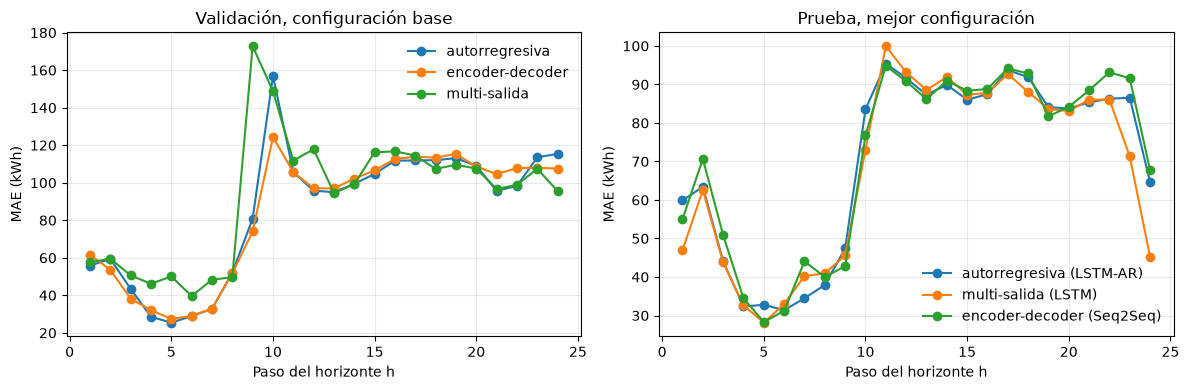

In [4]:
datos = PanelTensors(panel, "cuda" if torch.cuda.is_available() else "cpu")
origenes_validacion = daily_origins(CONFIG.validation_start, CONFIG.validation_end)
estrategias = {"LSTM-AR": "autorregresiva", "LSTM": "multi-salida", "Seq2Seq": "encoder-decoder"}
curvas = []
for config in base_configs():
    if config.label not in estrategias:
        continue
    corrida = load_run(ARTEFACTOS, run_id_of(config), datos)
    pronosticos = rolling_forecasts(
        lambda p, c: predict_positions(corrida.model, corrida.config, datos, corrida.normalizer, p, c),
        datos, origenes_validacion, config.label)
    pronosticos["error"] = (pronosticos["y"] - pronosticos["y_hat"]).abs()
    curva = pronosticos.groupby("horizon")["error"].mean().rename("mae").reset_index()
    curva["estrategia"] = estrategias[config.label]
    curvas.append(curva)
curvas = pd.concat(curvas)
curvas.to_csv(ARTEFACTOS / "detalle_redes" / "mae_horizonte_estrategias_validacion.csv", index=False)

prueba_horizonte = pd.read_csv(ARTEFACTOS / "detalle_redes" / "metricas_horizonte.csv")
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for estrategia, grupo in curvas.groupby("estrategia"):
    ejes[0].plot(grupo["horizon"], grupo["mae"], marker="o", label=estrategia)
for modelo, estrategia in estrategias.items():
    grupo = prueba_horizonte.loc[prueba_horizonte["modelo"].eq(modelo)]
    ejes[1].plot(grupo["horizon"], grupo["mae"], marker="o", label=f"{estrategia} ({modelo})")
for eje, titulo in zip(ejes, ["Validación, configuración base", "Prueba, mejor configuración"]):
    eje.set_xlabel("Paso del horizonte h"); eje.set_ylabel("MAE (kWh)"); eje.set_title(titulo)
    eje.grid(alpha=0.25); eje.legend(frameon=False)
fig.tight_layout(); fig.savefig(ARTEFACTOS / "estrategias_multipaso.png", dpi=180, bbox_inches="tight")
curvas.pivot(index="horizon", columns="estrategia", values="mae").iloc[[0, 5, 11, 17, 23]].round(2)

**Estrategias multi-paso.**

**Validación, configuración base.**
- El encoder-decoder es el mejor (MASE 0,876), seguido de la autorregresiva (0,878) y la multi-salida (0,889). La diferencia total es de 1,5 %.
- Las curvas por horizonte muestran dónde está la diferencia, no solo cuánto es.

**Primeras horas y rampa de la mañana.** Los orígenes son a medianoche, así que el paso `h` equivale a la hora `h-1`.
- Entre `h = 4` y `h = 7` (madrugada), la autorregresiva y el encoder-decoder tienen MAE de ~25-33 kWh, contra 40-50 de la multi-salida.
- En la rampa de la mañana (`h = 9-10`), la multi-salida tiene el pico más alto (173 kWh) y el encoder-decoder el más bajo (74 y 124 kWh).
- Conocer el calendario de cada hora futura dentro del decoder ayuda a ubicar el cambio de régimen.

**Final del horizonte.**
- En `h = 23-24` la autorregresiva acumula error (114-115 kWh), mientras la multi-salida baja a 96.
- Es el patrón esperado: la autorregresiva realimenta sus propias predicciones y el error se compone; la multi-salida predice cada paso directamente.

**Prueba, mejor configuración de cada una.**
- La multi-salida elegida tiene estado oculto 128, así que gana (0,799 contra 0,831 y 0,838). Esa comparación mezcla capacidad y estrategia.
- Aun así se repite el patrón: la multi-salida es claramente mejor en `h = 1` y `h = 24`, y la autorregresiva es mejor en `h = 7-8`.

**Costo.**
- La autorregresiva ejecuta 24 pasos secuenciales de la LSTM por ventana. Es la más lenta de entrenar e inferir (~53 s por epoch compartiendo GPU, contra ~11 s del encoder-decoder).
- La multi-salida es la más barata.

**Conclusión.** Con el mismo tamaño, el encoder-decoder con calendario futuro es la estrategia más precisa. La multi-salida es la de mejor relación costo-precisión, y la que mejor escala en capacidad.

### 5.2 Iteraciones de hiperparámetros

Cada iteración cambia un solo factor respecto a la configuración base. La LSTM se varía en `L`, meses de historia, normalización, estado oculto, capas y dropout, learning rate y batch; DLinear en `L`, historia y normalización; el MLP en tamaño, dropout y `L`.
- `iteraciones_entrenamiento.csv` tiene una fila por epoch: pérdidas, MAE y MASE de validación, parámetros, tiempos y memoria pico de GPU.
- `iteraciones_resumen.csv` resume cada corrida en su mejor epoch.

Todas las selecciones usan solo validación.

In [5]:
propias = resumen.loc[resumen["kind"].isin(["mlp", "dlinear", "nlinear", "lstm", "lstm_ar", "seq2seq"])]
tabla_iter = propias[["modelo", "lookback", "history_months", "normalization", "hidden_size", "num_layers",
                      "dropout", "learning_rate", "batch_size", "best_epoch", "epochs_run", "validation_mae",
                      "validation_mase", "total_parameters", "epoch_seconds_mean", "training_seconds",
                      "inference_seconds", "peak_gpu_memory_mb"]]
tabla_iter.sort_values(["modelo", "validation_mase"]).round(4)

,modelo,lookback,history_months,normalization,hidden_size,num_layers,dropout,learning_rate,batch_size,best_epoch,epochs_run,validation_mae,validation_mase,total_parameters,epoch_seconds_mean,training_seconds,inference_seconds,peak_gpu_memory_mb
28,DLinear,336,30,serie,64.0,1.0,0.0,0.0010,1024.0,9.0,13,95.4363,0.8729,16176,2.2348,29.0559,0.0158,198.3394
32,DLinear,168,30,ventana,64.0,1.0,0.0,0.0010,1024.0,3.0,7,93.0495,0.8804,8112,2.2975,16.0845,0.0163,194.8398
30,DLinear,168,12,serie,64.0,1.0,0.0,0.0010,1024.0,4.0,8,93.2588,0.8824,8112,0.9091,7.2759,0.0107,103.5117
1,DLinear,168,30,serie,64.0,1.0,0.0,0.0010,1024.0,4.0,8,93.8069,0.8860,8112,3.4071,27.2594,0.0191,196.0879
29,DLinear,168,3,serie,64.0,1.0,0.0,0.0010,1024.0,4.0,8,92.2001,0.8860,8112,0.2165,1.7356,0.0090,69.2222
27,DLinear,48,30,serie,64.0,1.0,0.0,0.0010,1024.0,4.0,8,89.7960,0.9449,2352,2.2755,18.2073,0.0160,191.4331
31,DLinear,168,30,global,64.0,1.0,0.0,0.0010,1024.0,2.0,6,95.3070,1.5946,8112,2.2509,13.5070,0.0154,194.8398
20,LSTM,168,30,serie,128.0,1.0,0.0,0.0010,1024.0,22.0,25,83.8501,0.8266,73752,27.7000,692.5158,0.0650,16894.9629
25,LSTM,168,30,serie,64.0,1.0,0.0,0.0010,256.0,25.0,25,86.2613,0.8342,20504,13.8925,347.3273,0.0261,8567.7544
24,LSTM,168,30,serie,64.0,1.0,0.0,0.0030,1024.0,24.0,25,85.4632,0.8353,20504,9.0131,225.3416,0.0262,8567.7661


In [6]:
# Efecto de cada factor sobre la LSTM y DLinear (MASE de validación).
base = {c.label: c for c in base_configs()}
def efecto(modelo, columna):
    referencia = base[modelo]
    filas = propias.loc[propias["modelo"].eq(modelo)].copy()
    otros = {"lookback": referencia.lookback, "history_months": referencia.history_months,
             "normalization": referencia.normalization, "hidden_size": referencia.hidden_size,
             "num_layers": referencia.num_layers, "dropout": referencia.dropout,
             "learning_rate": referencia.learning_rate, "batch_size": referencia.batch_size}
    otros.pop(columna)
    if columna == "num_layers":
        otros.pop("dropout")
    for clave, valor in otros.items():
        filas = filas.loc[np.isclose(filas[clave], valor) if isinstance(valor, float) else filas[clave].eq(valor)]
    return filas[[columna, "validation_mase", "best_epoch", "training_seconds"]].sort_values(columna)

for modelo, factores in {"LSTM": ["lookback", "history_months", "normalization", "hidden_size", "num_layers",
                                  "learning_rate", "batch_size"],
                         "DLinear": ["lookback", "history_months", "normalization"]}.items():
    for factor in factores:
        print(f"{modelo} | {factor}"); print(efecto(modelo, factor).round(4).to_string(index=False)); print()

LSTM | lookback
 lookback  validation_mase  best_epoch  training_seconds
       48           0.9081        23.0           97.9772
      168           0.8888        24.0          946.7206
      336           0.8839        25.0          422.7674

LSTM | history_months
 history_months  validation_mase  best_epoch  training_seconds
              3           1.3407        24.0           84.6663
             12           0.9652        23.0          457.1439
             30           0.8888        24.0          946.7206

LSTM | normalization
normalization  validation_mase  best_epoch  training_seconds
       global           1.4592         6.0          424.0513
        serie           0.8888        24.0          946.7206
      ventana           0.8676        25.0         1368.1633

LSTM | hidden_size
 hidden_size  validation_mase  best_epoch  training_seconds
        32.0           0.9480        24.0          136.1373
        64.0           0.8888        24.0          946.7206
       128.0   

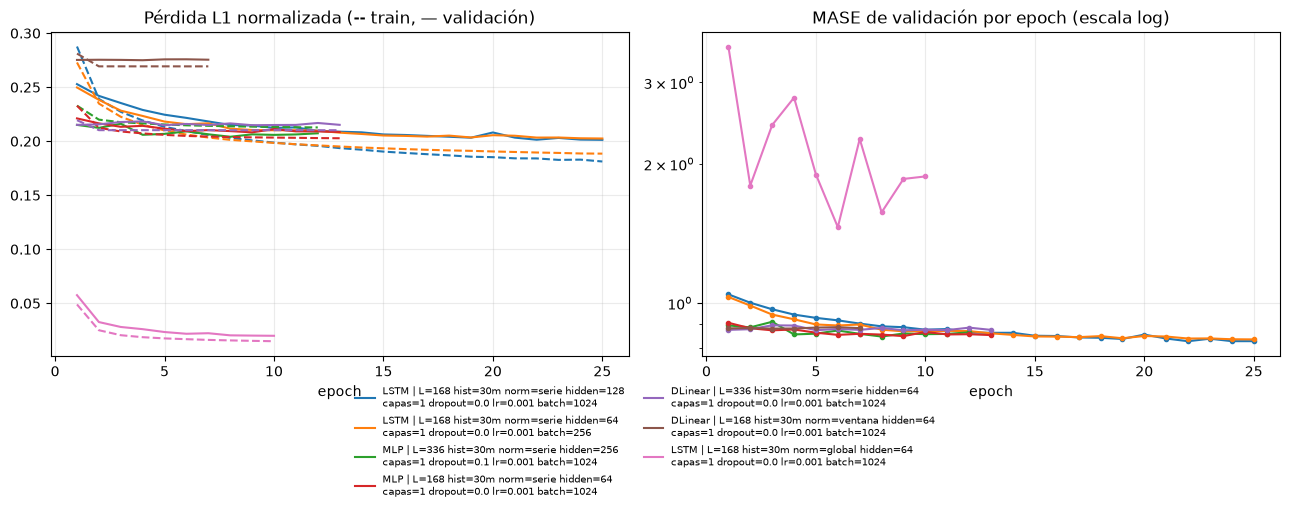

In [7]:
# Curvas de pérdida de varias iteraciones de la LSTM y del MLP.
seleccion = ["LSTM", "MLP", "DLinear"]
corridas = (propias.loc[propias["modelo"].isin(seleccion)]
            .sort_values("validation_mase").groupby("modelo").head(2)["run_id"].tolist())
corridas += propias.loc[propias["modelo"].eq("LSTM") & propias["normalization"].eq("global"), "run_id"].tolist()
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for run_id in corridas:
    curva = iteraciones.loc[iteraciones["run_id"].eq(run_id)]
    etiqueta = f"{curva['modelo'].iloc[0]} | {curva['configuracion'].iloc[0].replace(' capas', chr(10) + 'capas')}"
    linea, = ejes[0].plot(curva["epoch"], curva["train_loss"], linestyle="--")
    ejes[0].plot(curva["epoch"], curva["validation_loss"], color=linea.get_color(), label=etiqueta)
    ejes[1].plot(curva["epoch"], curva["validation_mase"], color=linea.get_color(), marker=".")
ejes[0].set_title("Pérdida L1 normalizada (-- train, — validación)"); ejes[0].set_xlabel("epoch")
ejes[1].set_title("MASE de validación por epoch (escala log)"); ejes[1].set_xlabel("epoch"); ejes[1].set_yscale("log")
for eje in ejes: eje.grid(alpha=0.25)
fig.legend(loc="lower center", ncol=2, fontsize=7, frameon=False, bbox_to_anchor=(0.5, -0.22))
fig.tight_layout(); fig.savefig(ARTEFACTOS / "curvas_perdida.png", dpi=180, bbox_inches="tight")

In [8]:
# ¿Menor pérdida de entrenamiento implica mejor MASE de validación?
finales = iteraciones.loc[iteraciones["validation_mase"].notna()].copy()
ultimo = finales.sort_values("epoch").groupby("run_id").tail(1).merge(
    propias[["run_id", "kind", "normalization"]], on="run_id")
comparables = ultimo.loc[ultimo["normalization"].eq("serie")]
print("Correlación de Spearman entre corridas (pérdida de train final vs MASE de validación):",
      round(comparables[["train_loss", "validation_mase"]].corr(method="spearman").iloc[0, 1], 3))
pares = []
for run_id, curva in finales.groupby("run_id"):
    curva = curva.sort_values("epoch")
    baja = curva["train_loss"].diff().lt(0)
    sube = curva["validation_mase"].diff().gt(0)
    pares.append({"run_id": run_id, "epochs": len(curva), "train_baja_y_val_sube": int((baja & sube).sum())})
pares = pd.DataFrame(pares)
print("Epochs en que la pérdida de train bajó pero el MASE de validación subió:",
      int(pares["train_baja_y_val_sube"].sum()), "de", int(pares["epochs"].sum() - len(pares)))

Correlación de Spearman entre corridas (pérdida de train final vs MASE de validación): 0.848
Epochs en que la pérdida de train bajó pero el MASE de validación subió: 135 de 522


**Iteraciones.** Se cambia un factor a la vez sobre la LSTM base (MASE de validación 0,889) y DLinear (0,886).

**Normalización: el factor más importante.**
- La normalización global (una sola media y desviación para todos los clientes) lleva el MASE a 1,46 en la LSTM y a 1,59 en DLinear.
- El consumo medio va de ~5 kWh (MT_001) a ~49 000 kWh (MT_362), así que la pérdida queda dominada por los clientes grandes y los pequeños se ignoran.
- La normalización por ventana (estilo RevIN) mejora un poco a la por serie: 0,868 contra 0,889 en la LSTM, 0,880 contra 0,886 en DLinear.

**Longitud de contexto.**
- `L = 48` empeora a ambos (0,908 y 0,945) porque no ve el ciclo semanal.
- `L = 336` mejora un poco (0,884 y 0,873); es la mejor configuración de DLinear y del MLP.

**Historia.** La LSTM depende mucho de la cantidad de datos (1,341 con 3 meses, 0,965 con 12, 0,889 con 30). DLinear es insensible.

**Capacidad.**
- Con estado oculto 32 / 64 / 128, la LSTM da 0,948 / 0,889 / 0,827: el factor con mayor mejora.
- Dos capas dan 0,847. Dropout 0,2 entre capas no ayuda (0,850): no hay sobreajuste dentro del presupuesto.

**Optimización.**
- Con learning rate 3e-4 / 1e-3 / 3e-3, el MASE es 0,982 / 0,889 / 0,835.
- Con batch 256 / 1024 / 4096, el MASE es 0,834 / 0,889 / 0,994.
- En este rango, más pasos de gradiente o pasos más grandes ayudan. Esto, y que casi todas las LSTM tengan su mejor epoch en 22-25 de un máximo de 25, indica que las LSTM terminaron **subentrenadas**: el tope de 25 epochs las limita y sus diferencias reflejan en parte el presupuesto.
- DLinear, NLinear y el MLP convergen en 3-12 epochs y paran por early stopping.

**MLP.** Con 64 unidades sin dropout (0,848) empata con 256 con dropout 0,1 (0,853). La capacidad extra no aporta.

**¿Menor pérdida de entrenamiento implica mejor MASE de validación?**
- **Entre configuraciones** con la misma normalización, sí en promedio: la correlación de Spearman entre la pérdida de train final y el MASE de validación es 0,85.
- **Dentro de una corrida, no siempre.** En 135 de 522 transiciones entre epochs (26 %) la pérdida de train bajó mientras el MASE de validación subió. Pasa sobre todo en los modelos lineales y el MLP, que se ajustan en pocas epochs.
- **El contraejemplo más claro es la normalización global.** Tiene la pérdida de train más baja de todas las corridas (~0,016) y el peor MASE (1,46). La pérdida está en otra escala y mide el ajuste a los clientes grandes.
- La pérdida solo compara corridas con la misma escala. La selección debe hacerse con la métrica de validación en kWh o MASE.

**Memoria.** El pico de GPU de la LSTM no cambia con el batch (8,57 GB con 256 y con 4096), así que no lo fija el lote de entrenamiento. Con `L = 336` o estado oculto 128 sube a ~17 GB, más que los 16 GB de la tarjeta, y Windows recurre a memoria compartida del sistema.

### Sensibilidad a la historia de entrenamiento

Gráfica 3 del laboratorio: MASE de validación con 3, 12 y 30 meses de historia antes del 1 de julio de 2014.
- **Modelos:** seasonal naive, LightGBM global, DLinear, la mejor recurrente según validación y PatchTST.
- **Referencia:** Chronos-Bolt zero-shot no se entrena, así que aparece como línea constante.
- **Escala MASE:** usa siempre toda la historia previa al origen, igual que `backtest`, para que los puntos sean comparables.

In [9]:
sensibilidad = pd.read_csv(ARTEFACTOS / "sensibilidad_historia.csv")
plot_history_sensitivity(sensibilidad, ARTEFACTOS / "sensibilidad_historia.png")
sensibilidad.pivot(index="modelo", columns="history_months", values="mase").round(4)

history_months,3,12,30
modelo,,,
Chronos-Bolt (zero-shot),0.7731,0.7731,0.7731
DLinear,0.8860,0.8824,0.8860
LightGBM,1.3089,1.2711,1.3817
PatchTST,0.9107,0.8818,0.8906
SeasonalNaive24,0.9944,0.9944,0.9944
Seq2Seq,1.6656,0.9276,0.8756


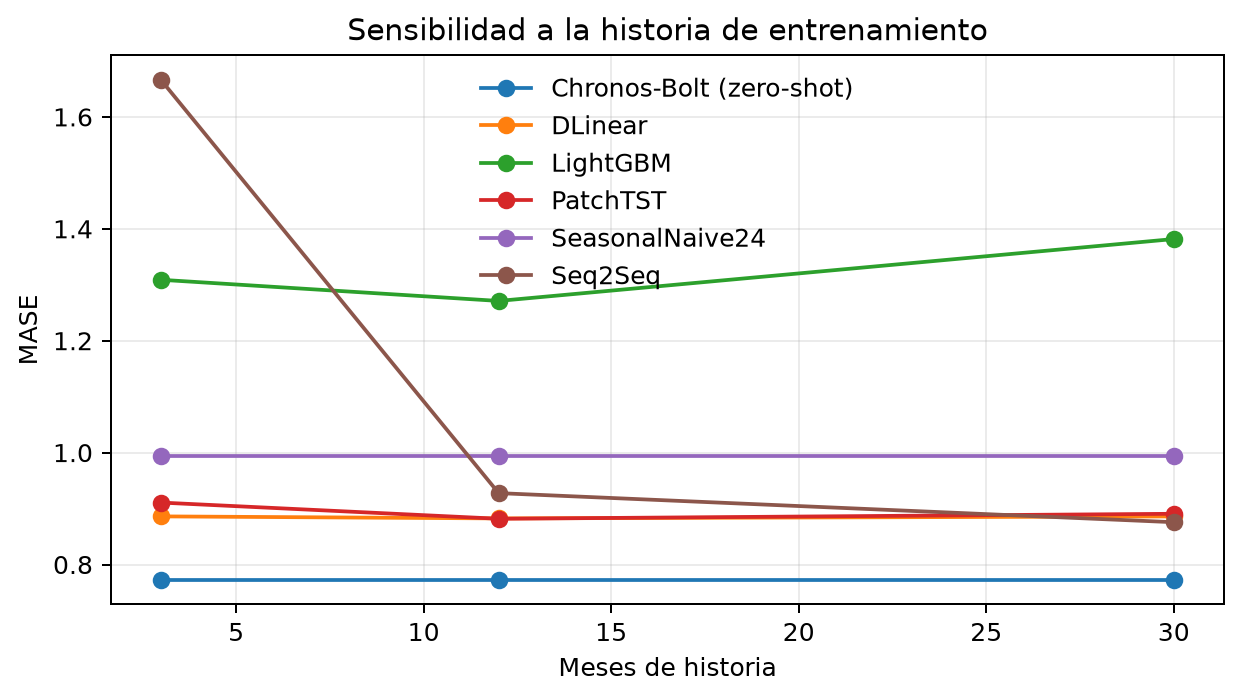

In [10]:
from IPython.display import Image
Image(str(ARTEFACTOS / "sensibilidad_historia.png"))

**Sensibilidad a la historia.** MASE de validación con 3, 12 y 30 meses de entrenamiento.

**Los modelos se separan en tres grupos.**
- **Casi insensibles:** DLinear (0,886 / 0,882 / 0,886) y PatchTST (0,911 / 0,882 / 0,891). Con 3 meses ya tienen ~2 000 ventanas por cliente para sus pocos parámetros efectivos. PatchTST incluso es un poco mejor con 12 meses que con 30, aunque la diferencia es de 0,01.
- **Muy dependiente:** Seq2Seq (1,666 / 0,928 / 0,876). Con 3 meses no aprende la estacionalidad semanal ni la diferencia entre temporadas; el early stopping corta en la epoch 7. Necesita al menos un año.
- **No monótono:** LightGBM (1,309 / 1,271 / 1,382). Su recursión hora a hora acumula error en cualquier caso. Con 30 meses incluye 2012, y una explicación posible es que esos niveles de consumo se parecen menos a los de 2014.

**Referencias constantes.**
- Chronos-Bolt zero-shot (0,773) es mejor que cualquier modelo entrenado en validación; N-HiTS, el mejor entrenado, da 0,794.
- SeasonalNaive24 (0,994) queda por encima de todas las redes con 12 o más meses.
- Con poca historia (3 meses), Chronos y los modelos lineales son la opción segura. Con 30 meses, las redes más grandes (N-HiTS, LSTM con estado oculto 128) alcanzan o superan a Chronos en prueba.

### Pronóstico probabilístico (DeepAR)

DeepAR se entrena con verosimilitud t de Student. De sus trayectorias se obtienen P10, P50 y P90. Se reporta:
- la pinball loss promedio en esos tres cuantiles;
- la cobertura empírica del intervalo P10-P90, cuyo valor nominal es 80 %.

 pinball_loss  cobertura_p10_p90   mase
      33.8137             0.6108 1.2495


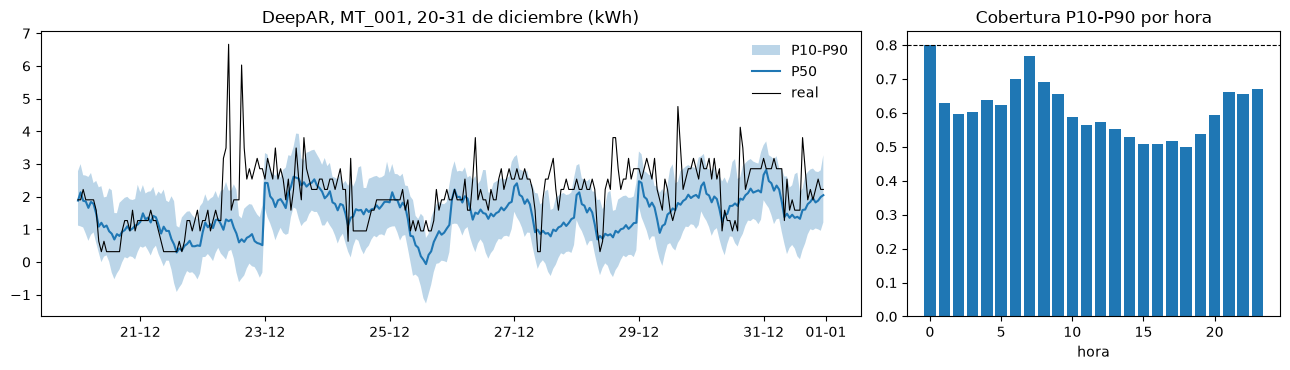

In [11]:
cuantiles = pd.read_csv(ARTEFACTOS / "cuantiles_deepar.csv", parse_dates=["ds"])
real = panel.rename_axis("ds").reset_index().melt(id_vars="ds", var_name="unique_id", value_name="y")
cuantiles = cuantiles.merge(real, on=["unique_id", "ds"])
cuantiles["dentro"] = cuantiles["y"].between(cuantiles["p10"], cuantiles["p90"])
print(resultados.loc[resultados["modelo"].eq("DeepAR"), ["pinball_loss", "cobertura_p10_p90", "mase"]].round(4).to_string(index=False))
por_hora = cuantiles.groupby(cuantiles["ds"].dt.hour)["dentro"].mean()
ventana = cuantiles.loc[cuantiles["unique_id"].eq("MT_001") & cuantiles["ds"].between("2014-12-20", "2014-12-31 23:00")]
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ejes[0].fill_between(ventana["ds"], ventana["p10"], ventana["p90"], alpha=0.3, label="P10-P90")
ejes[0].plot(ventana["ds"], ventana["p50"], label="P50"); ejes[0].plot(ventana["ds"], ventana["y"], color="black", lw=0.8, label="real")
ejes[0].set_title("DeepAR, MT_001, 20-31 de diciembre (kWh)"); ejes[0].legend(frameon=False)
ejes[0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d-%m"))
ejes[1].bar(por_hora.index, por_hora.values); ejes[1].axhline(0.8, color="black", ls="--", lw=0.8)
ejes[1].set_title("Cobertura P10-P90 por hora"); ejes[1].set_xlabel("hora")
fig.tight_layout(); fig.savefig(ARTEFACTOS / "intervalos_deepar.png", dpi=180, bbox_inches="tight")

**Pronóstico probabilístico.**
- **Pinball loss** (promedio de P10, P50 y P90): 33,8 kWh.
- **Cobertura del intervalo P10-P90:** 61 % contra el 80 % nominal. Los intervalos son demasiado estrechos, es decir, el modelo está sobreconfiado.

**Cobertura por hora.**
- Solo llega al 80 % a medianoche (`h = 1`). Hay un segundo máximo entre las 6 h y las 8 h (~69-77 %).
- Baja a ~50 % entre las 14 h y las 19 h, justo donde el error absoluto es mayor.
- Esto sugiere que la dispersión de la t de Student, ajustada en escala z por serie, no crece lo suficiente con el horizonte ni con el nivel de consumo diurno.

**Pronóstico puntual.**
- La mediana de DeepAR (MASE 1,249) es peor que SeasonalNaive24.
- Muestra un error grande en la rampa de las 7-8 h (MAE de 171 kWh a las 8 h). El muestreo autorregresivo propaga el error del inicio del día.

**Posibles mejoras, no exploradas aquí:**
- más pasos de entrenamiento o early stopping con pinball en lugar de la verosimilitud;
- verosimilitud por cuantiles;
- calibración conformal de los intervalos con los residuos de validación.

### 5.3 Modelo local contra global

La mejor red propia según validación se entrena de dos formas:
- **Local:** un modelo por cliente, con la misma configuración y el mismo early stopping, solo con las ventanas de ese cliente.
- **Global:** el modelo ya entrenado con los 100 clientes.

Los 10 clientes se eligen con la semilla del experimento y el MASE se mide en prueba.

In [12]:
local_global = pd.read_csv(ARTEFACTOS / "local_vs_global.csv")
print("Modelo base:", local_global["modelo_base"].iloc[0])
print("MASE medio local:", round(local_global["mase_local"].mean(), 4), "| global:", round(local_global["mase_global"].mean(), 4),
      "| clientes donde gana el global:", int(local_global["mejora_global"].gt(0).sum()), "de", len(local_global))
local_global.sort_values("mejora_global", ascending=False).round(4)

Modelo base: LSTM
MASE medio local: 0.9669 | global: 0.8228 | clientes donde gana el global: 10 de 10


,unique_id,modelo_base,consumo_medio_kwh,mase_local,mase_global,validation_mase_local,epochs_local,training_seconds_local,mejora_global
2,MT_066,LSTM,37.5384,1.5578,1.1243,1.7027,3,26.6704,0.4335
7,MT_225,LSTM,324.9644,0.8809,0.6486,0.9109,4,31.2810,0.2323
4,MT_075,LSTM,47.3580,1.0799,0.9262,0.7697,21,95.1042,0.1538
5,MT_195,LSTM,439.2863,1.0411,0.8908,0.9480,13,64.5825,0.1504
6,MT_207,LSTM,846.1679,0.9875,0.8808,1.0478,12,61.0588,0.1067
3,MT_069,LSTM,161.2907,0.8994,0.8103,0.7121,20,91.3250,0.0891
1,MT_054,LSTM,69.1188,0.7512,0.6645,0.7058,9,50.1347,0.0867
9,MT_295,LSTM,262.7258,0.8459,0.7657,0.6683,23,95.5230,0.0802
8,MT_238,LSTM,400.4991,1.1425,1.0675,0.7867,15,73.4043,0.0750
0,MT_040,LSTM,112.6686,0.4825,0.4497,0.3761,10,53.6040,0.0328


**Local contra global.**
- **Configuración:** la mejor red propia, la LSTM multi-salida con estado oculto 128. Para cada uno de los 10 clientes se entrenó un modelo solo con sus ventanas, con la misma configuración y early stopping.
- **Resultado:** el modelo global gana en los 10 clientes. El MASE medio de prueba es 0,823 global contra 0,967 local, 15 % menos error.

**Dónde gana más el global.**
- En los clientes chicos o irregulares: MT_066 (37,5 kWh medios) pasa de 1,558 local a 1,124 global, y MT_225 de 0,881 a 0,649.
- En esos casos el modelo local para en 3-4 epochs: con ~21 000 ventanas muy correlacionadas, 74 000 parámetros se sobreajustan enseguida.
- Compartir la red entre clientes funciona como aumento de datos y regularización: aprende la forma diaria y semanal común y se adapta a cada nivel por la normalización por serie.

**Costo.** Un modelo local tarda 27-96 s. Con 100 clientes serían ~1,5-2 h y 100 conjuntos de pesos, contra ~11 min y un solo modelo para el global.

### Sensibilidad a la semilla y reentrenamiento mensual

- **Semillas:** la mejor red según validación se repite con tres semillas.
- **Reentrenamiento mensual:** la mejor red propia (LSTM) y la mejor red en general (N-HiTS) se reentrenan al inicio de octubre, noviembre y diciembre, con ventana expandible y el mismo presupuesto elegido en validación: epochs para la LSTM, pasos para N-HiTS. Cada modelo pronostica solo su mes. La fila «sin reentrenar» compara contra los pesos fijos al 30 de septiembre.

In [13]:
semillas = pd.read_csv(ARTEFACTOS / "semillas.csv")
print(semillas.round(4).to_string(index=False))
print("Desviación estándar del MASE (validación, prueba):",
      round(semillas["validation_mase"].std(ddof=1), 4), round(semillas["test_mase"].std(ddof=1), 4))
mensual = pd.read_csv(ARTEFACTOS / "reentrenamiento_mensual_redes.csv")
mensual.round(4)

modelo  seed  validation_mase  test_mase
N-HiTS  3092           0.7936     0.7701
N-HiTS     1           0.7967     0.7668
N-HiTS     2           0.7947     0.7689
Desviación estándar del MASE (validación, prueba): 0.0016 0.0017


,mes_reentrenamiento,modelo,mae,rmse,wape,mape,mase
0,2014-10,LSTM,83.5164,794.3697,0.0792,NaN,0.7519
1,2014-11,LSTM,60.6015,530.9852,0.0732,NaN,0.6918
2,2014-12,LSTM,55.1027,353.9803,0.0723,NaN,0.9258
3,total,LSTM,66.4700,588.8866,0.0753,NaN,0.7909
4,sin reentrenar,LSTM,67.9859,603.2771,0.0771,NaN,0.7994
5,2014-10,N-HiTS,84.7178,806.0153,0.0803,NaN,0.7376
6,2014-11,N-HiTS,62.1039,563.0737,0.0750,NaN,0.6795
7,2014-12,N-HiTS,57.4011,383.7723,0.0753,NaN,0.8927
8,total,N-HiTS,68.1391,609.8535,0.0772,NaN,0.7709
9,sin reentrenar,N-HiTS,66.7843,608.1080,0.0757,NaN,0.7701


**Semillas.**
- N-HiTS repetido con las semillas 3092, 1 y 2 da MASE de prueba de 0,770, 0,767 y 0,769.
- La desviación estándar es 0,0017 en prueba y 0,0016 en validación.
- La diferencia con iTransformer (0,015) es unas 9 desviaciones. Contra Chronos (0,04) y la LSTM (0,03) es aún mayor. Esas brechas no son ruido de inicialización.
- Ese cálculo vale para N-HiTS, que converge con early stopping. Las LSTM terminaron subentrenadas y pueden tener más varianza entre semillas.
- La semilla 3092 reproduce exactamente la corrida original: el MASE de prueba del evaluador vectorizado coincide con el de `backtest` hasta el sexto decimal.

**Reentrenamiento mensual** de la LSTM con estado oculto 128, con ventana expandible y 22 epochs fijas:

| Mes | MASE reentrenando | MASE sin reentrenar |
|---|---|---|
| Octubre | 0,752 | |
| Noviembre | 0,692 | |
| Diciembre | 0,926 | |
| Total | 0,791 | 0,799 |

- El total mejora 1,1 % (MAE de 68,0 a 66,5 kWh). La mejora es pequeña: el patrón del panel cambia poco en tres meses, y el modelo sin reentrenar ya incluye la normalización por serie.
- El seasonal naive mensual de referencia da 0,948, 0,904 y 1,216. La red mantiene una ventaja de ~20-25 % en cada mes.
- En operación, reentrenar mensualmente cuesta tres entrenamientos de ~10 min y aporta poco. Bastaría con reentrenar trimestralmente o ante cambios detectados en el error.

### Error por hora del día y semana navideña

Desgloses pedidos en la sección 4 para cada red: `artifacts/detalle_redes/metricas_{horizonte,hora,cliente,navidad}.csv`.

modelo,DLinear,DeepAR,LSTM,LSTM-AR,MLP,N-HiTS,NLinear,PatchTST,Seq2Seq,TCN,iTransformer
ds,,,,,,,,,,,
2014-12-22,0.893,1.435,0.814,0.912,0.858,0.803,0.873,0.880,0.881,0.863,0.766
2014-12-23,0.846,1.217,0.781,0.898,0.817,0.787,0.814,0.851,0.880,0.862,0.771
2014-12-24,1.611,1.883,1.655,1.677,1.659,1.610,1.573,1.560,1.694,1.616,1.745
2014-12-25,4.421,3.041,3.221,3.675,4.231,3.953,4.421,4.239,3.281,3.932,2.744
2014-12-26,2.987,4.278,1.859,1.208,1.561,0.931,2.850,1.054,1.417,1.494,1.027
2014-12-27,0.934,1.581,1.010,0.934,0.928,0.869,0.973,0.983,0.956,1.049,0.876
2014-12-28,0.762,1.188,0.850,0.860,0.834,0.822,0.812,0.807,0.825,0.803,0.739


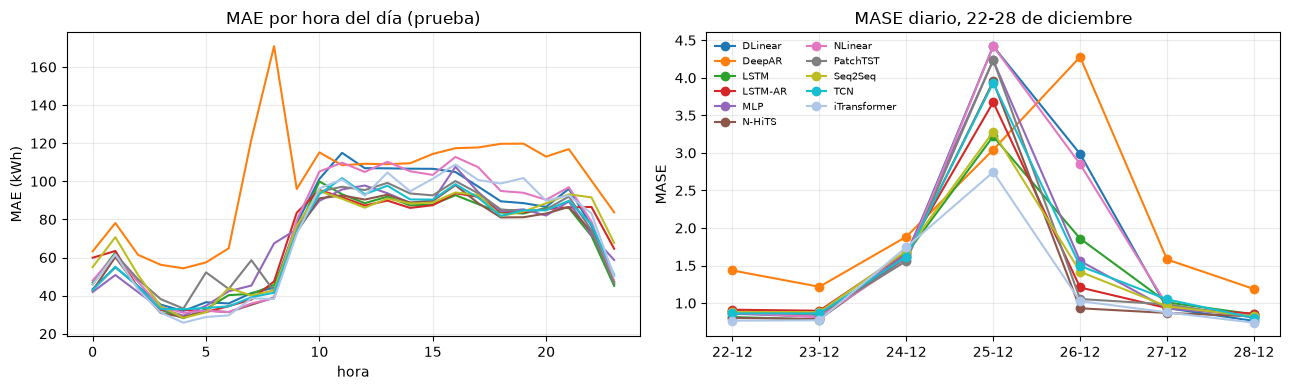

In [14]:
por_hora = pd.read_csv(ARTEFACTOS / "detalle_redes" / "metricas_hora.csv")
navidad = pd.read_csv(ARTEFACTOS / "detalle_redes" / "metricas_navidad.csv", parse_dates=["ds"])
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje in ejes: eje.set_prop_cycle(color=plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2])
for modelo, grupo in por_hora.groupby("modelo"):
    ejes[0].plot(grupo["hour"], grupo["mae"], label=modelo)
for modelo, grupo in navidad.groupby("modelo"):
    ejes[1].plot(grupo["ds"].dt.strftime("%d-%m"), grupo["mase"], marker="o", label=modelo)
ejes[0].set_title("MAE por hora del día (prueba)"); ejes[0].set_xlabel("hora"); ejes[0].set_ylabel("MAE (kWh)")
ejes[1].set_title("MASE diario, 22-28 de diciembre"); ejes[1].set_ylabel("MASE")
for eje in ejes: eje.grid(alpha=0.25)
ejes[1].legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(ARTEFACTOS / "error_hora_navidad_redes.png", dpi=180, bbox_inches="tight")
navidad.pivot(index="ds", columns="modelo", values="mase").round(3)

**Hora del día y semana navideña.**

**Hora del día.**
- El error de todas las redes sigue el perfil de consumo: ~25-35 kWh de MAE entre las 3 h y las 6 h, y ~85-110 kWh entre las 10 h y las 17 h.
- El primer paso (hora 0) no es el más fácil: a medianoche varios clientes cambian de régimen. En las horas de oficina el nivel y la variabilidad son mayores.

**Semana navideña** (MASE diario del 22 al 28 de diciembre).
- Todas las redes empeoran el 24 (~1,6) y sobre todo el 25 (2,7 a 4,4).
- **El 25 de diciembre** está marcado como feriado en las covariables:
  - Los modelos que usan calendario lo aprovechan en distinta medida: iTransformer (2,74), DeepAR (3,04), LSTM (3,22) y Seq2Seq (3,28) quedan muy por debajo de los univariados DLinear y NLinear (4,42) y PatchTST (4,24).
  - El MLP (4,23) y N-HiTS (3,95) reciben el mismo indicador pero lo aprovechan menos. Con pocos feriados en train, el indicador pesa poco.
- **El 26 de diciembre** separa a los modelos que copian el día anterior: DLinear (2,99), NLinear (2,85) y DeepAR (4,28) arrastran el patrón del feriado. N-HiTS (0,93), iTransformer (1,03) y PatchTST (1,05) se recuperan de inmediato.
- En el agregado de la semana (`mase_navidad`), iTransformer es el mejor (1,24), seguido de N-HiTS (1,40) y Seq2Seq (1,42).

### Observaciones para la discusión (sección 8)

1. **Ranking.** Con el mismo panel y protocolo, las redes globales bien configuradas superan a todos los baselines y a LightGBM. Las tres mejores (N-HiTS 0,770, iTransformer 0,785, LSTM con estado oculto 128 0,799) también superan a Chronos zero-shot (0,809) en prueba. En validación, Chronos sigue siendo el mejor (0,773), así que la ventaja de las redes es pequeña y depende del periodo.
2. **Normalizar por serie es indispensable.** La normalización global multiplica el MASE por 1,6-1,8. La por ventana aporta otra mejora pequeña.
3. **Escalado de NeuralForecast.** Su escalado por ventana divide por `eps` en las ventanas constantes de clientes con tramos en cero (por ejemplo MT_223) y produce pérdidas NaN. Se resolvió con un z-score por serie ajustado en train y `scaler_type="identity"`.
4. **Lineales contra recurrentes.** Los modelos lineales (DLinear y NLinear) son el piso barato: 0,85-0,87 en menos de 30 s de entrenamiento. Las recurrentes solo los superan con más capacidad y más epochs.
5. **Las LSTM terminaron subentrenadas.** Mejor epoch en 22-25 de 25 posibles, y mejoran con learning rate más alto o batch más pequeño. Un presupuesto mayor probablemente cerraría parte de la brecha con N-HiTS.
6. **Estrategias multi-paso.** Con el mismo tamaño, el encoder-decoder con calendario futuro es el más preciso. La autorregresiva acumula error al final del día y es la más lenta. La multi-salida es la más eficiente y la mejor al escalar.
7. **Modelo global contra local.** El global gana en 10 de 10 clientes (−15 % de MASE), sobre todo en los clientes chicos, donde un modelo local se sobreajusta.
8. **Historia.** Las redes recurrentes necesitan al menos 12 meses. Los lineales y PatchTST son estables con 3. LightGBM no mejora con más historia.
9. **Sensibilidad a la semilla.** La desviación estándar del MASE de prueba de N-HiTS es 0,0017, mucho menor que las diferencias entre los primeros puestos.
10. **Reentrenamiento mensual.** Mejora apenas 1 % a la LSTM. No justifica su costo frente a un reentrenamiento menos frecuente.
11. **DeepAR.** Queda sobreconfiado (cobertura P10-P90 de 61 % contra 80 % nominal) y su mediana es peor que el seasonal naive. Habría que calibrar sus intervalos antes de usarlos.
12. **Navidad.** Es el punto débil común. El indicador de feriado ayuda el 25, sobre todo a iTransformer y a las recurrentes. Los modelos que copian el día anterior fallan además el 26.
13. **Mediciones de tiempo.** Varias corridas compartieron la GPU y sus tiempos son cotas superiores. Los tiempos de inferencia de prueba están dominados por `backtest` (~10 min por modelo) y no reflejan el costo de la red.